# 🌱 Explainable Long-Term Soil Health Forecasting Framework
## LUCAS 2018 — Complete Pipeline (Stages 1–9)

| Stage | Description |
|-------|-------------|
| 1 | Data ingestion, cleaning & merging |
| 2 | Exploratory Data Analysis |
| 3 | Imputation & log transforms |
| 4 | Sustainable Health Index (SHI) |
| 5 | Feature engineering |
| 6 | XGBoost & Random Forest — regression |
| 6b | Hyperparameters + extended metrics + confusion matrix + ROC |
| 7 | SHAP explainability & diagnostic reports |
| 8 | What-if scenario analysis |
| 9 | Save outputs |

**Files to upload:** `LUCAS-SOIL-2018.csv`, `BulkDensity_2018_final-2.csv`, `LUCAS_Text_All_10032025.csv`, `data_preparation.py`, `soil_health_pipeline.py`

## Step 0 — Install dependencies

In [ ]:
!pip install xgboost shap openpyxl pyarrow scikit-learn seaborn -q
print('All dependencies installed.')

All dependencies installed.


## Step 0b — Upload all 5 files

In [ ]:
from google.colab import files
print('Upload: 3 CSV datasets + data_preparation.py + soil_health_pipeline.py')
uploaded = files.upload()
print('Uploaded:', list(uploaded.keys()))

Upload: 3 CSV datasets + data_preparation.py + soil_health_pipeline.py


Saving soil_health_pipeline.py to soil_health_pipeline.py
Saving LUCAS-SOIL-2018.csv to LUCAS-SOIL-2018.csv
Saving LUCAS_Text_All_10032025.csv to LUCAS_Text_All_10032025.csv
Saving data_preparation.py to data_preparation.py
Saving BulkDensity_2018_final-2.csv to BulkDensity_2018_final-2.csv
Uploaded: ['soil_health_pipeline.py', 'LUCAS-SOIL-2018.csv', 'LUCAS_Text_All_10032025.csv', 'data_preparation.py', 'BulkDensity_2018_final-2.csv']


In [ ]:
CORE_PATH    = 'LUCAS-SOIL-2018.csv'
BD_PATH      = 'BulkDensity_2018_final-2.csv'
TEXTURE_PATH = 'LUCAS_Text_All_10032025.csv'
OUTPUT_DIR   = 'lucas_output'

import os
os.makedirs(OUTPUT_DIR, exist_ok=True)
print(f'Output directory ready: {OUTPUT_DIR}/')

Output directory ready: lucas_output/


---
## Stage 1 — Data Ingestion, Cleaning & Merging

In [ ]:
from data_preparation import build_master_dataframe, missing_value_report, bdl_summary

master_df = build_master_dataframe(
    core_path    = CORE_PATH,
    bd_path      = BD_PATH,
    texture_path = TEXTURE_PATH,
    lod_strategy = 'zero',
)
print(f'Master DataFrame: {master_df.shape[0]:,} rows x {master_df.shape[1]} columns')
master_df.head(3)

Loading core chemistry …
  Core      : 18,984 rows × 36 cols
Loading bulk density …
  Bulk dens : 6,271 rows × 4 cols
Loading texture (best year per point) …
  Texture   : 27,819 rows × 13 cols
Merging …
Master DataFrame: 18,984 rows × 54 columns
  Points with BD      : 6,172
  Points with Texture : 18,984
Master DataFrame: 18,984 rows x 54 columns


,Depth,pH_CaCl2,pH_H2O,EC,OC,CaCO3,P,N,K,OC (20-30 cm),...,Lucas2018,Coarse,Clay,Sand,Silt,PSDAvailable,TextureFromSurvey,USDA,ISSS,HAS_TEXTURE
POINT_ID,,,,,,,,,,,,,,,,,,,,,
47862690,0-20 cm,4.1,4.81,8.73,12.4,3.0,0.0,1.1,101.9,NaN,...,YES,2.0,23.0,23.0,54.0,Yes,2009.0,silt loam,silty loam,1
47882704,0-20 cm,4.1,4.93,5.06,16.7,1.0,0.0,1.3,51.2,NaN,...,YES,6.0,15.0,47.0,38.0,Yes,2009.0,loam,silty loam,1
47982688,0-20 cm,4.1,4.85,12.53,47.5,1.0,12.3,3.1,114.8,NaN,...,YES,4.0,23.0,11.0,66.0,Yes,2009.0,silt loam,silty loam,1


In [ ]:
print('=== Below-Detection-Limit Summary ===')
display(bdl_summary(master_df))
print('\n=== Missing Value Report (top 20) ===')
display(missing_value_report(master_df).head(20))

=== Below-Detection-Limit Summary ===


,column,bdl_count,bdl_pct
5,P,4976,26.21
7,K,39,0.21
3,OC,32,0.17
6,N,14,0.07
4,CaCO3,9,0.05
0,pH_H2O,0,0.00
1,pH_CaCl2,0,0.00
2,EC,0,0.00
8,Ox_Al,0,0.00
9,Ox_Fe,0,0.00



=== Missing Value Report (top 20) ===


,missing_count,missing_pct
CaCO3 (20-30 cm),18970,99.93
BD 20-30,18845,99.27
OC (20-30 cm),18843,99.26
Ox_Al,16474,86.78
Ox_Fe,16474,86.78
BD_0_20,13318,70.15
BD_10_20,13293,70.02
BD_0_10,12837,67.62
CaCO3,7763,40.89
Coarse,2709,14.27


---
## Stage 2 — Exploratory Data Analysis

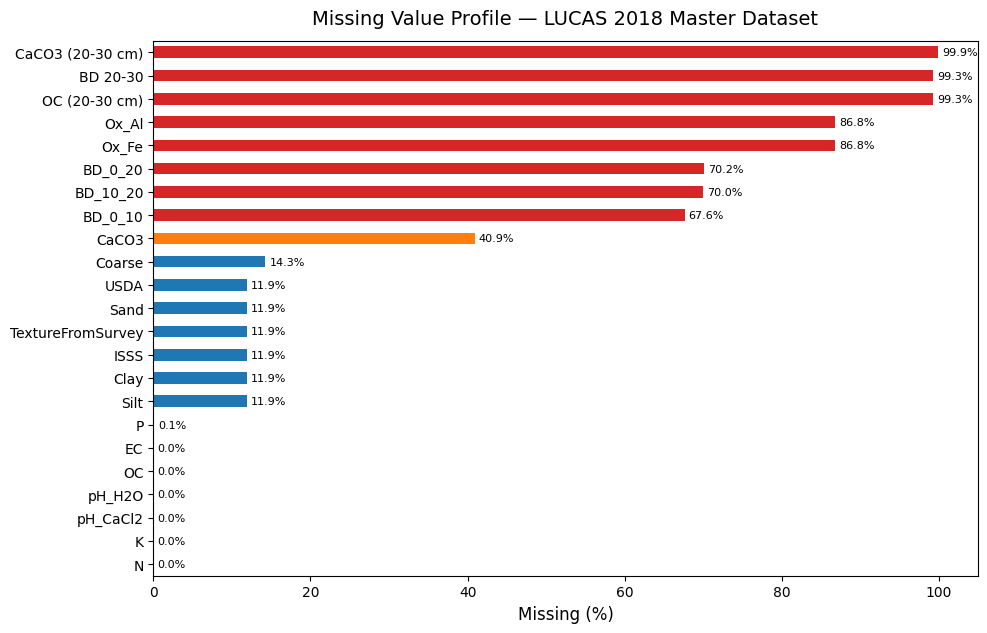

In [ ]:
from soil_health_pipeline import (
    plot_missing_values, plot_chemistry_distributions,
    plot_correlation_heatmap, plot_spatial_distribution, plot_land_cover_stats
)
plot_missing_values(master_df, OUTPUT_DIR)

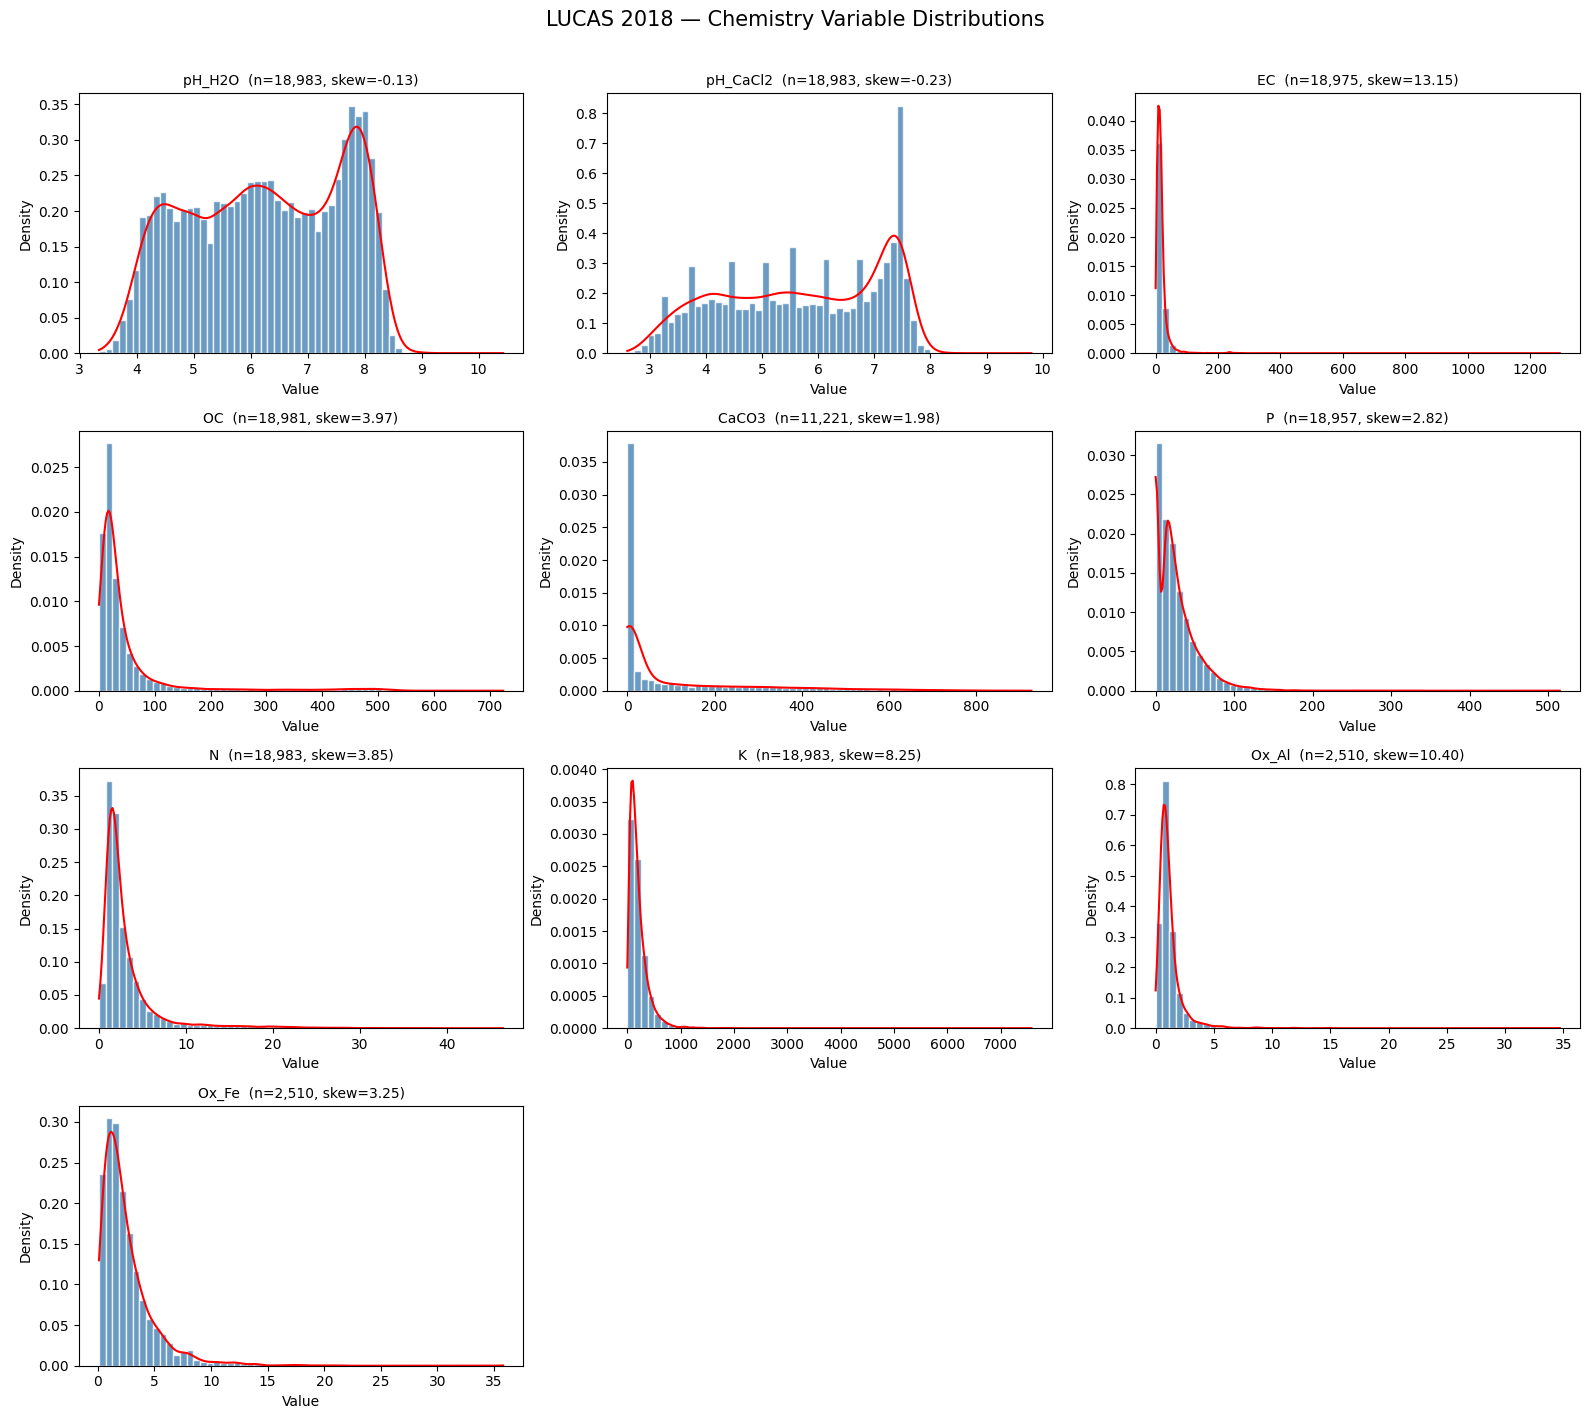

In [ ]:
plot_chemistry_distributions(master_df, OUTPUT_DIR)

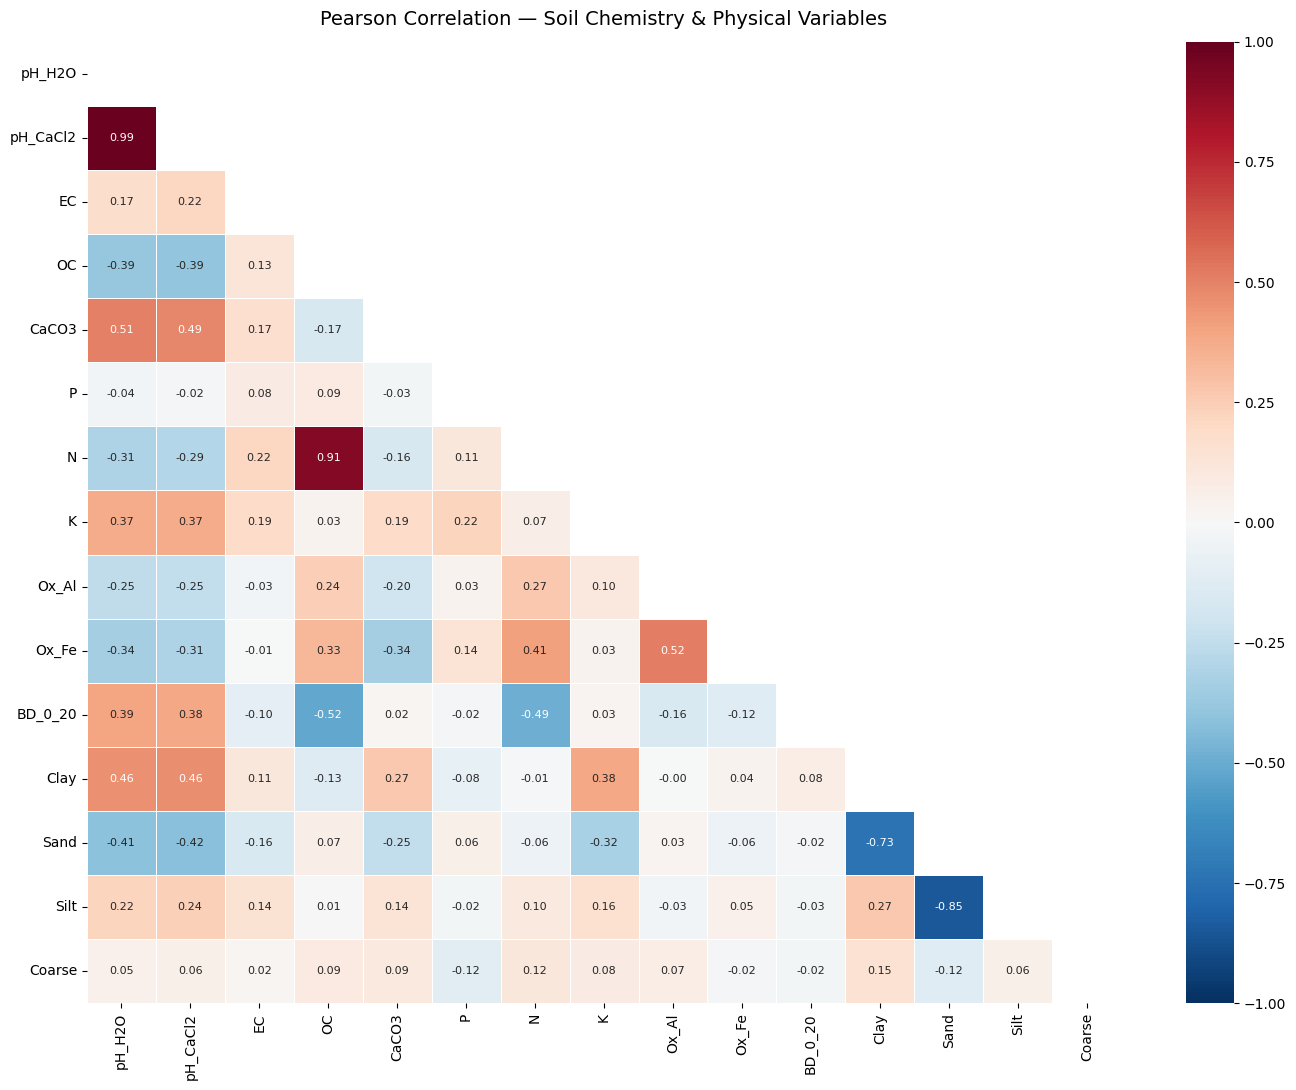

In [ ]:
plot_correlation_heatmap(master_df, OUTPUT_DIR)

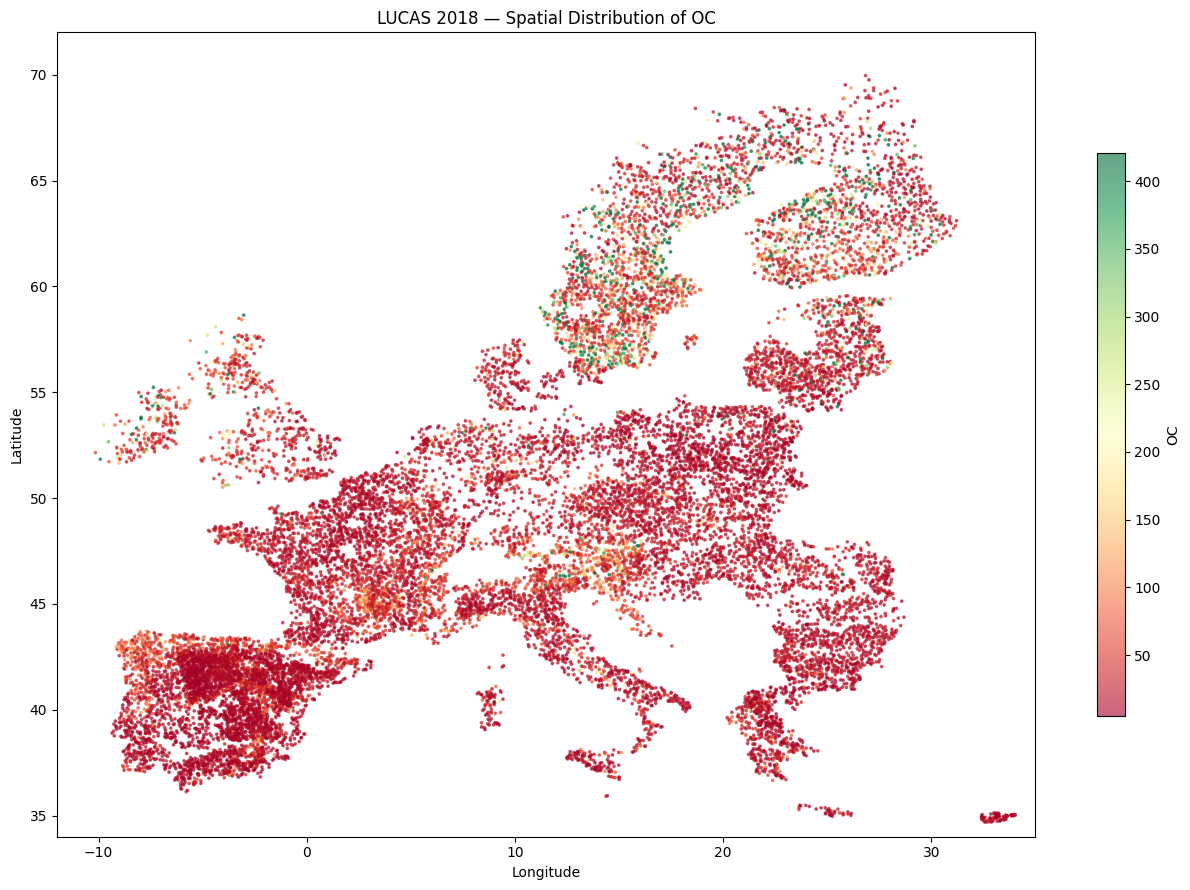

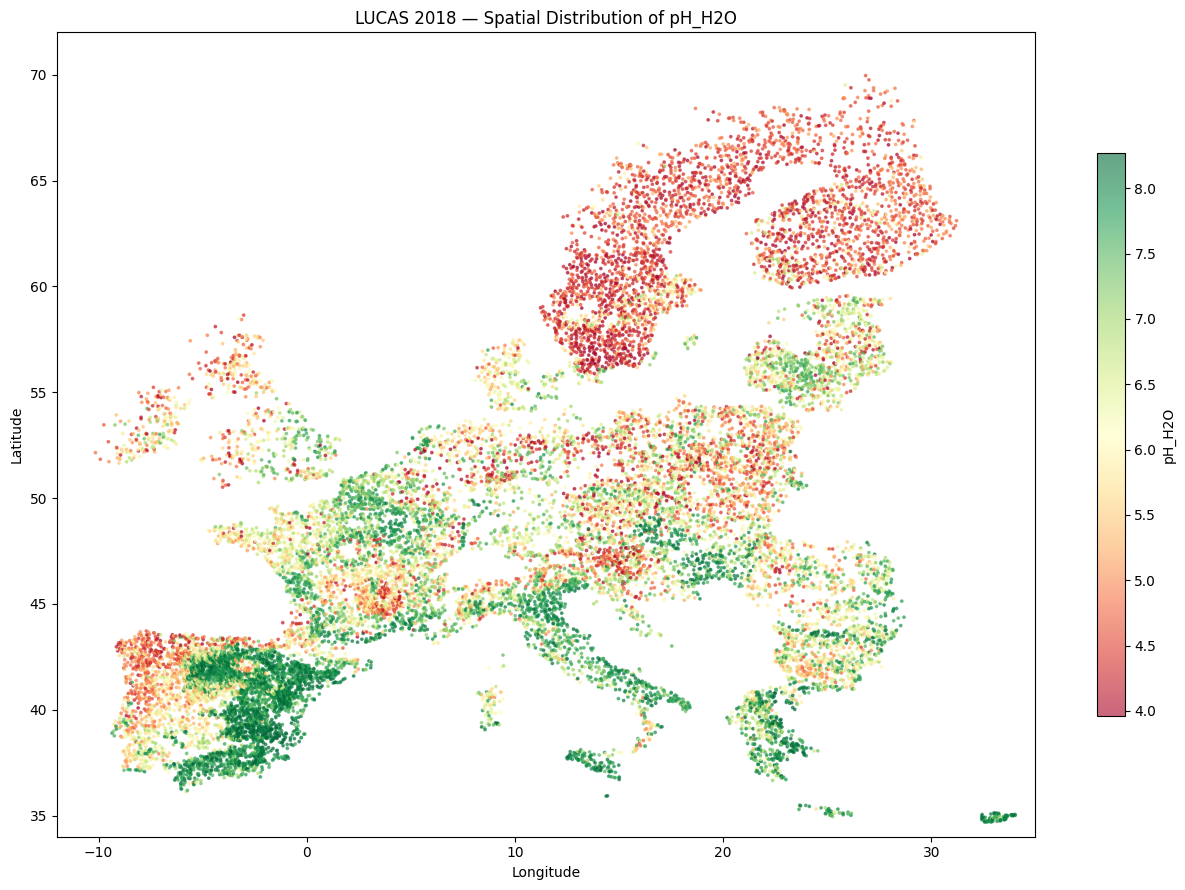

In [ ]:
plot_spatial_distribution(master_df, OUTPUT_DIR, color_col='OC')
plot_spatial_distribution(master_df, OUTPUT_DIR, color_col='pH_H2O')

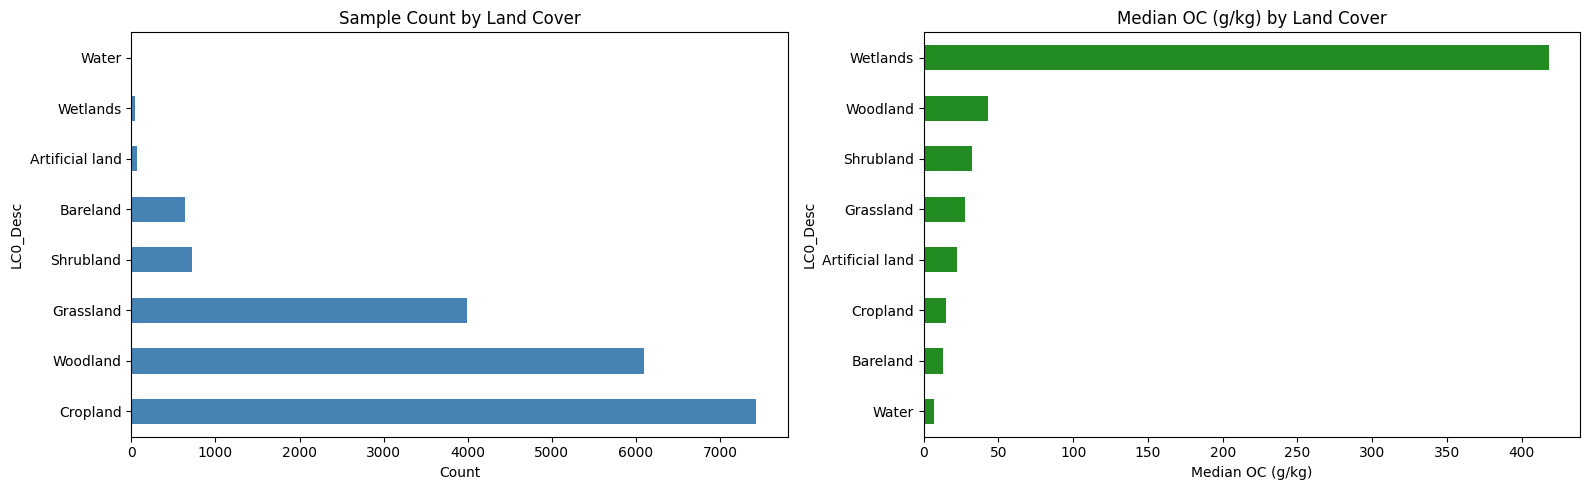

In [ ]:
plot_land_cover_stats(master_df, OUTPUT_DIR)

---
## Stage 3 — Imputation & Log Transforms

In [ ]:
from soil_health_pipeline import impute_features, apply_log_transforms

df = impute_features(master_df)
df = apply_log_transforms(df)

core_chem = ['pH_H2O', 'OC', 'N', 'P', 'K', 'EC']
print('Missing in core chemistry after imputation:')
print(df[core_chem].isna().sum())
print(f'Shape after imputation: {df.shape}')

Missing in core chemistry after imputation:
pH_H2O    0
OC        0
N         0
P         0
K         0
EC        0
dtype: int64
Shape after imputation: (18984, 71)


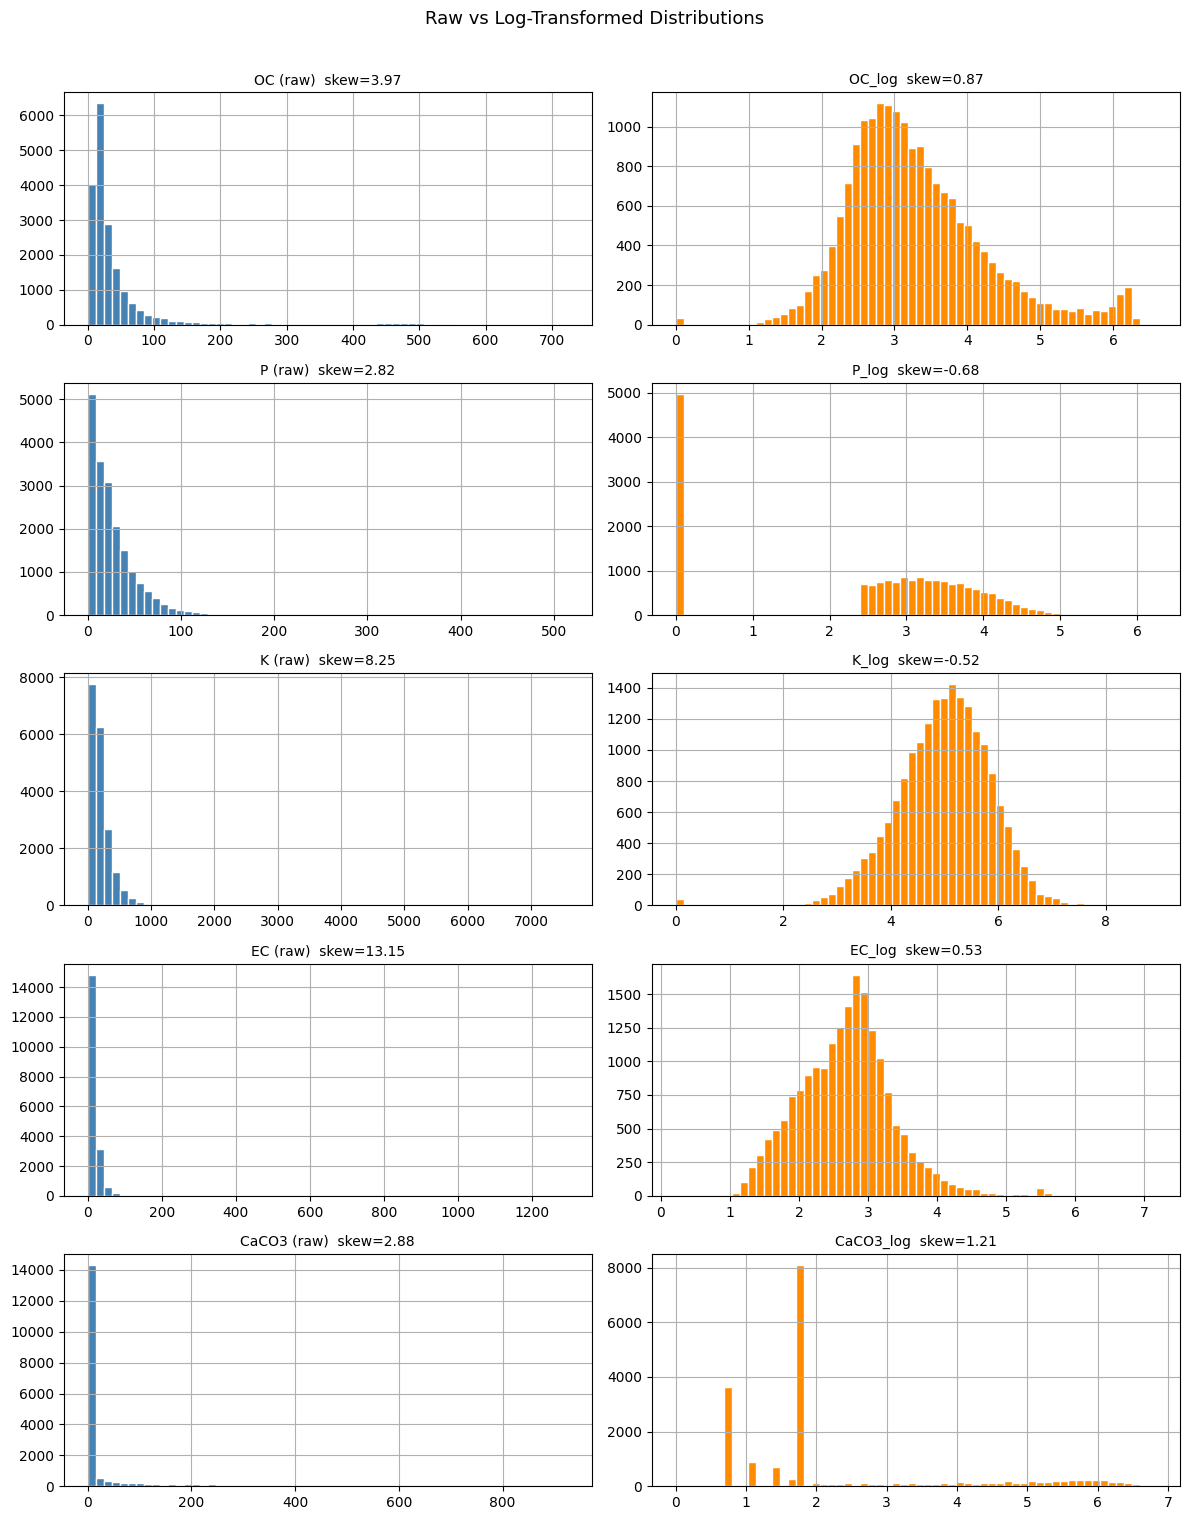

In [ ]:
import matplotlib.pyplot as plt

log_cols = ['OC', 'P', 'K', 'EC', 'CaCO3']
existing = [c for c in log_cols if c in df.columns and f'{c}_log' in df.columns]

fig, axes = plt.subplots(len(existing), 2, figsize=(12, len(existing) * 3))
for i, col in enumerate(existing):
    df[col].dropna().hist(bins=60, ax=axes[i, 0], color='steelblue', edgecolor='white')
    axes[i, 0].set_title(f'{col} (raw)  skew={df[col].skew():.2f}', fontsize=10)
    df[f'{col}_log'].dropna().hist(bins=60, ax=axes[i, 1], color='darkorange', edgecolor='white')
    axes[i, 1].set_title(f'{col}_log  skew={df[col+"_log"].skew():.2f}', fontsize=10)

plt.suptitle('Raw vs Log-Transformed Distributions', fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/log_transforms.png', dpi=150, bbox_inches='tight')
plt.show()

---
## Stage 4 — Sustainable Health Index (SHI)

| Indicator | Weight | Scoring logic |
|-----------|--------|---------------|
| pH (H₂O) | 25% | Triangular: optimum 6.0–7.0 |
| OC (g/kg) | 25% | Saturating: min(OC/40, 1) |
| N (g/kg)  | 15% | Linear: 0–4 g/kg |
| EC (mS/m) | 15% | Inverse: 1 − EC/400 |
| P (mg/kg) | 10% | Triangular: optimum 20–60 |
| K (mg/kg) | 10% | Saturating: min(K/400, 1) |

Risk classes: **Critical** (<0.25) | **High** (0.25–0.50) | **Moderate** (0.50–0.75) | **Low** (>0.75)

In [ ]:
from soil_health_pipeline import compute_shi, plot_shi_distribution, plot_shi_spatial, plot_shi_by_land_cover

df = compute_shi(df)
print(f'SHI computed for {df["SHI"].notna().sum():,} points')

import pandas as pd
score_cols = ['SHI', 'SHI_LABEL'] + [c for c in df.columns if c.startswith('score_')]
display(df[score_cols].dropna().describe())

SHI computed for 18,984 points


,SHI,score_pH_H2O,score_OC,score_N,score_P,score_K,score_EC
count,18984.000000,18984.000000,18984.000000,18984.000000,18984.000000,18984.000000,18984.000000
mean,0.669041,0.717308,0.602677,0.569020,0.653106,0.452491,0.954214
std,0.137978,0.246085,0.307922,0.285358,0.415976,0.292603,0.058701
min,0.124800,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.570600,0.548000,0.327500,0.325000,0.000000,0.211750,0.948500
50%,0.669400,0.740000,0.545000,0.500000,0.880000,0.381750,0.965125
75%,0.766200,0.972000,1.000000,0.850000,1.000000,0.651750,0.979750
max,0.996700,1.000000,1.000000,1.000000,1.000000,1.000000,0.999400


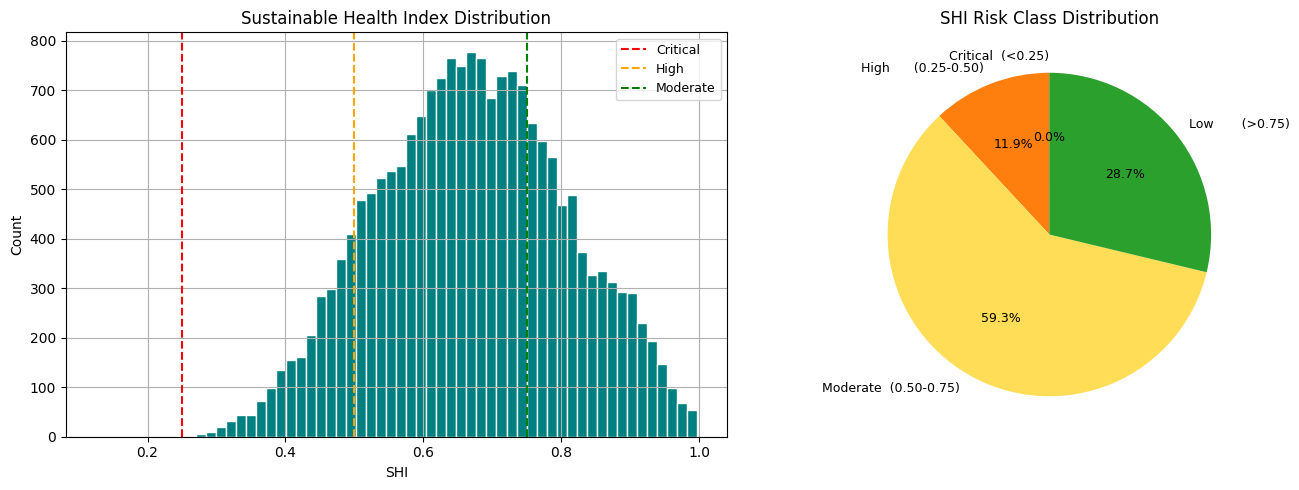

In [ ]:
plot_shi_distribution(df, OUTPUT_DIR)

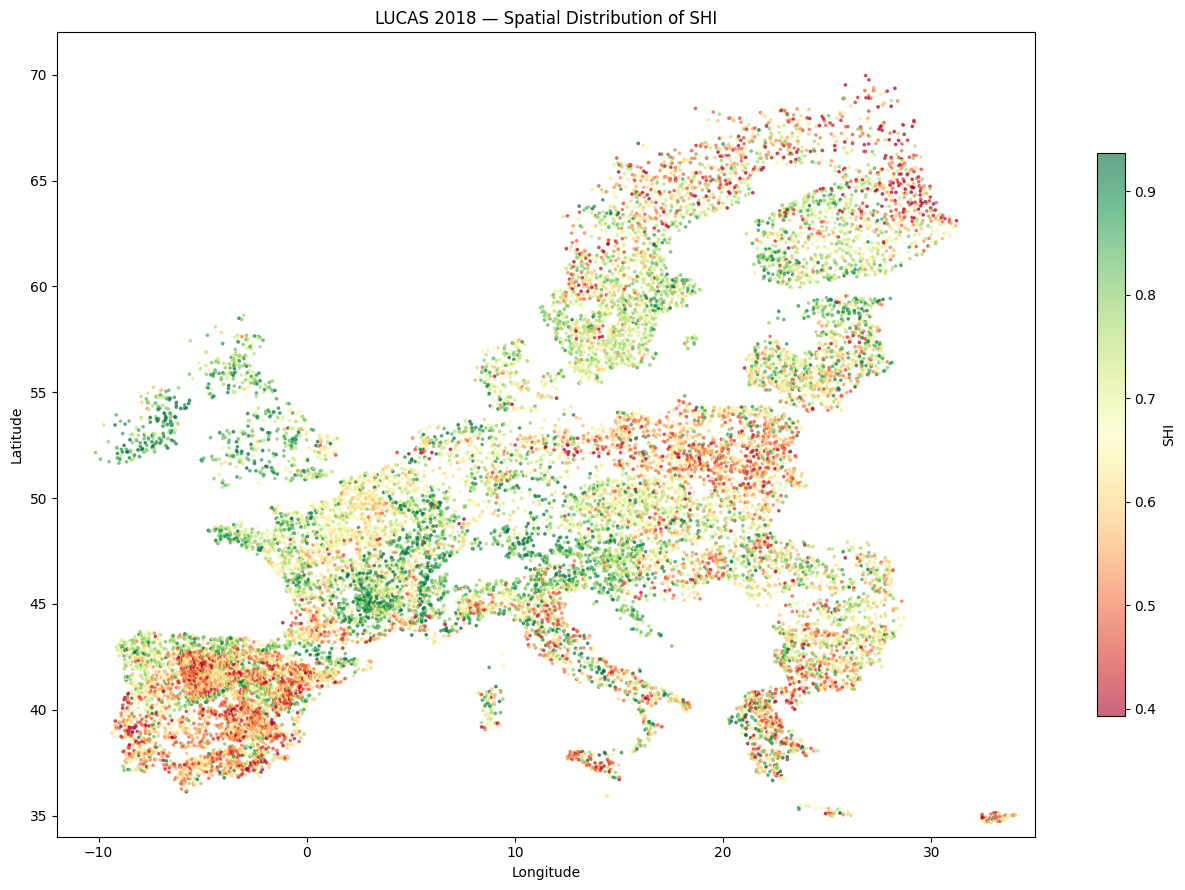

In [ ]:
plot_shi_spatial(df, OUTPUT_DIR)

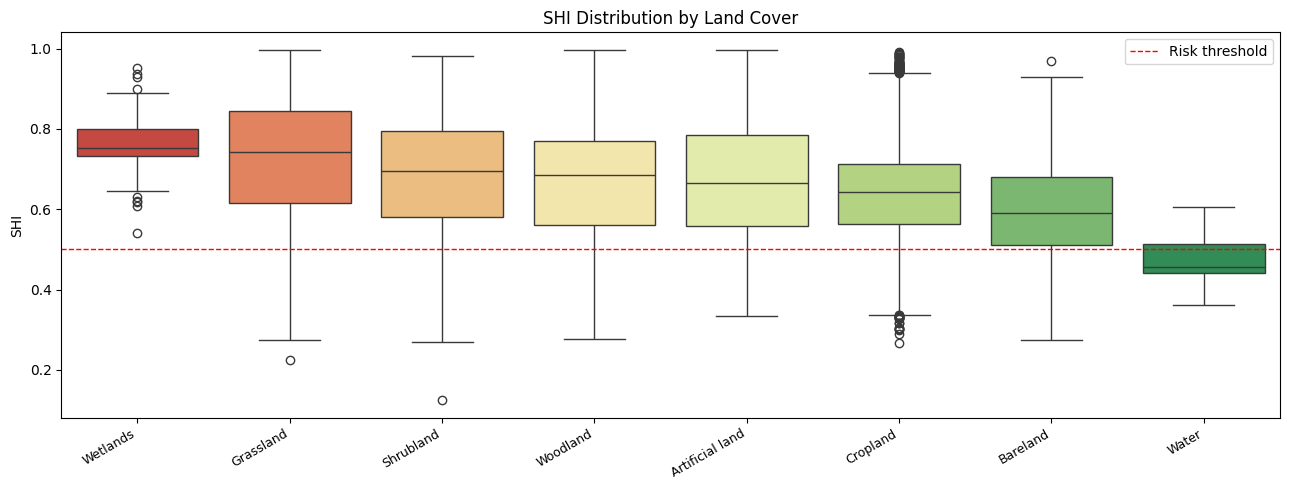

In [ ]:
plot_shi_by_land_cover(df, OUTPUT_DIR)

---
## Stage 5 — Feature Engineering

In [ ]:
from soil_health_pipeline import encode_categorical, build_feature_set, scale_features

df = encode_categorical(df)
X, y, feature_names = build_feature_set(df)
X_scaled, scaler = scale_features(X)

print(f'Feature matrix : {X_scaled.shape[0]:,} rows x {X_scaled.shape[1]} features')
print(f'SHI target     : mean={y.mean():.3f}  std={y.std():.3f}  min={y.min():.3f}  max={y.max():.3f}')
print(f'\nAll features:')
for i, f in enumerate(feature_names, 1):
    print(f'  {i:3d}. {f}')

Feature matrix : 18,984 rows x 41 features
SHI target     : mean=0.669  std=0.138  min=0.125  max=0.997

All features:
    1. pH_H2O
    2. pH_CaCl2
    3. OC
    4. N
    5. P
    6. K
    7. EC
    8. CaCO3
    9. BD_0_20
   10. OC_log
   11. P_log
   12. K_log
   13. EC_log
   14. CaCO3_log
   15. Clay
   16. Sand
   17. Silt
   18. Coarse
   19. TH_LAT
   20. TH_LONG
   21. Elev
   22. NUTS_0
   23. LC
   24. LU
   25. Depth
   26. pH_CaCl2_MISSING
   27. pH_H2O_MISSING
   28. EC_MISSING
   29. OC_MISSING
   30. CaCO3_MISSING
   31. P_MISSING
   32. N_MISSING
   33. K_MISSING
   34. BD_0_10_MISSING
   35. BD_10_20_MISSING
   36. BD_0_20_MISSING
   37. Coarse_MISSING
   38. Clay_MISSING
   39. Sand_MISSING
   40. Silt_MISSING
   41. TextureFromSurvey_MISSING


---
## Stage 6 — XGBoost & Random Forest Regression

In [ ]:
from soil_health_pipeline import train_and_evaluate, plot_model_performance, plot_feature_importance

# Set run_hyperparam_search=True for full tuning (~5-10 min extra)
model_results = train_and_evaluate(X_scaled, y, cv=5, run_hyperparam_search=False)

import pandas as pd
reg_summary = pd.DataFrame({name: res['metrics'] for name, res in model_results.items()}).T
print('Regression metrics:')
display(reg_summary)

Regression metrics:


,R2_test,MAE_test,RMSE_test,R2_cv_mean,R2_cv_std
XGBoost,0.997215,0.004742,0.007332,0.997270,0.000291
RandomForest,0.988310,0.010186,0.015022,0.988718,0.000789


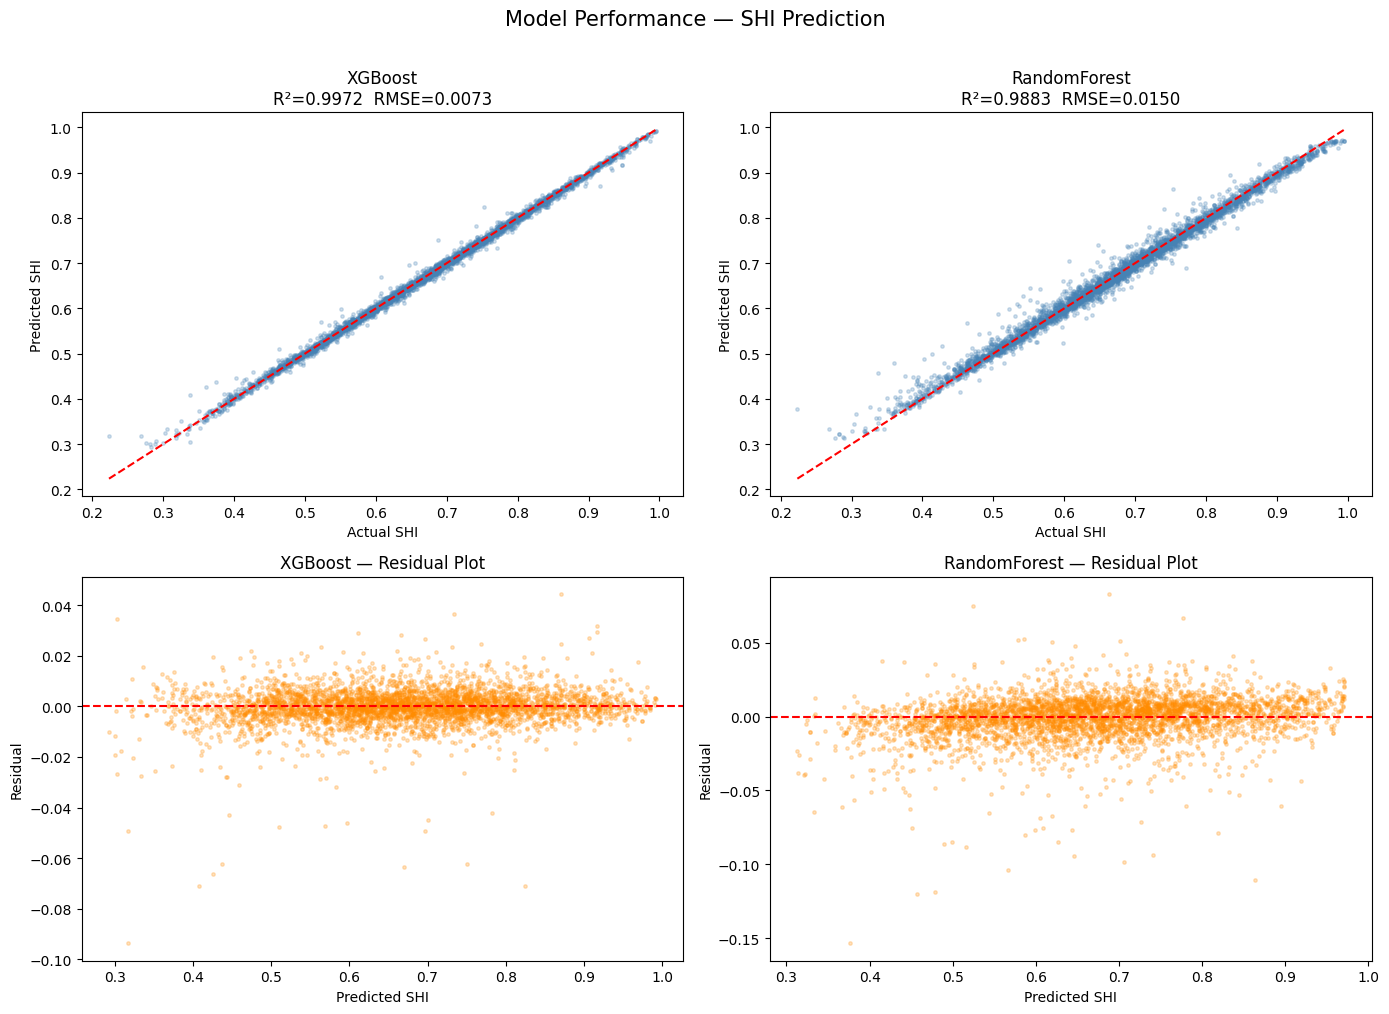

In [ ]:
plot_model_performance(model_results, OUTPUT_DIR)

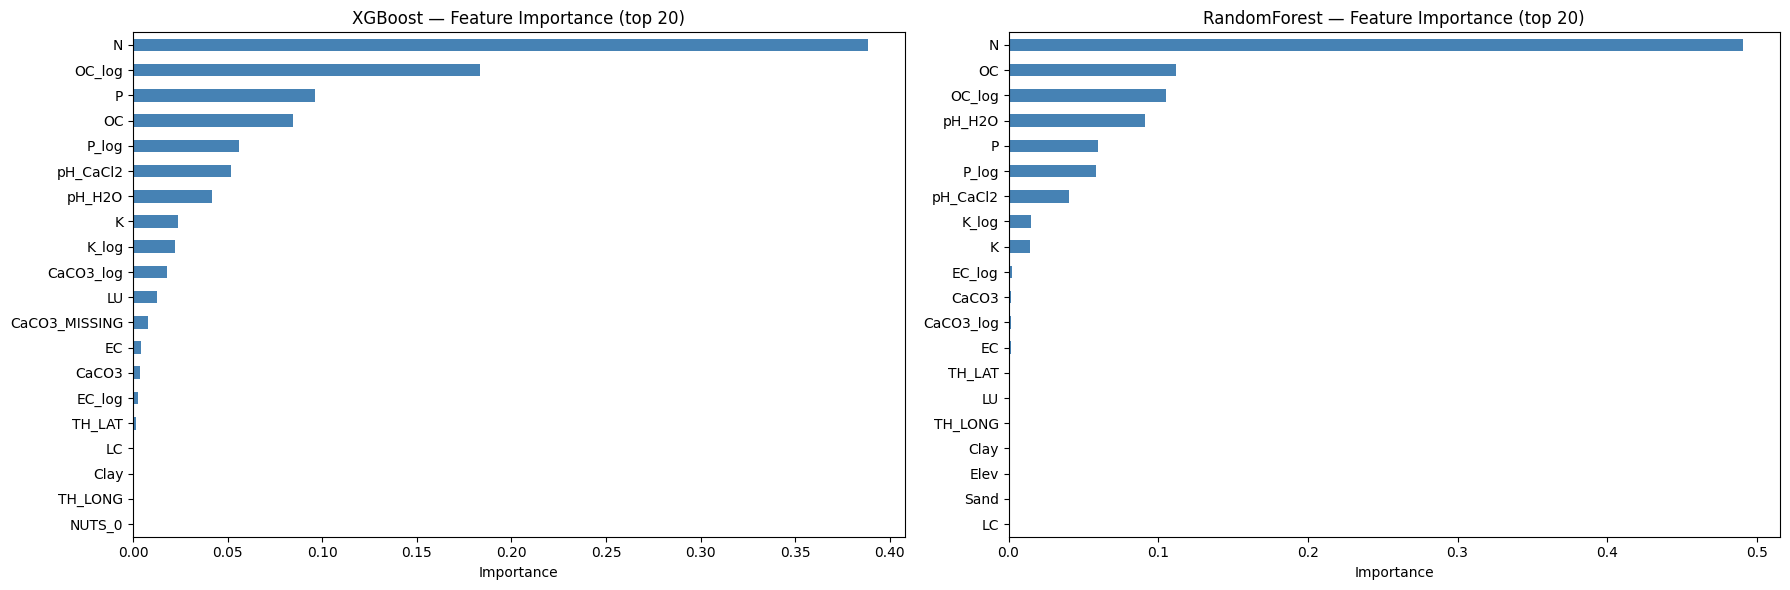

In [ ]:
plot_feature_importance(model_results, feature_names, OUTPUT_DIR, top_n=20)

In [ ]:
best_name  = max(model_results, key=lambda k: model_results[k]['metrics']['R2_test'])
best_model = model_results[best_name]['model']
print(f'Best regression model : {best_name}')
m = model_results[best_name]['metrics']
print(f'  R²       = {m["R2_test"]:.4f}')
print(f'  RMSE     = {m["RMSE_test"]:.4f}')
print(f'  MAE      = {m["MAE_test"]:.4f}')
print(f'  CV R²    = {m["R2_cv_mean"]:.4f} ± {m["R2_cv_std"]:.4f}')

Best regression model : XGBoost
  R²       = 0.9972
  RMSE     = 0.0073
  MAE      = 0.0047
  CV R²    = 0.9973 ± 0.0003


---
## Stage 6b — Hyperparameters, Extended Metrics, Confusion Matrix & ROC

This section covers what's missing from a standard ML evaluation:
- **Hyperparameter table** — every parameter used by each model
- **Extended regression metrics** — MAPE, Max Error, Explained Variance
- **Classification models** — trained on SHI risk class (Critical / High / Moderate / Low)
- **Confusion matrices** — normalised and raw count, for both classifiers
- **Per-class report** — precision, recall, F1, support per risk class
- **ROC curves** — one-vs-rest with per-class AUC
- **Unified comparison table** — regression vs classification side-by-side

In [ ]:
# Define classification target from SHI_CLASS column
y_class = df.loc[X.index, 'SHI_CLASS']
print(y_class.value_counts().sort_index())

SHI_CLASS
0        2
1     2259
2    11266
3     5457
Name: count, dtype: Int64


In [ ]:
from soil_health_pipeline import display_hyperparameters

print('REGRESSION MODELS — Full Hyperparameter Table')
hp_df = display_hyperparameters(model_results)

REGRESSION MODELS — Full Hyperparameter Table
╔══════════════════════════════════════════════════════╗
║           MODEL HYPERPARAMETERS                      ║
╚══════════════════════════════════════════════════════╝

── XGBoost ──────────────────────────────
  base_score                          = None
  booster                             = None
  callbacks                           = None
  colsample_bylevel                   = None
  colsample_bynode                    = None
  colsample_bytree                    = 0.8
  device                              = None
  early_stopping_rounds               = None
  enable_categorical                  = True
  eval_metric                         = rmse
  feature_types                       = None
  feature_weights                     = None
  gamma                               = None
  grow_policy                         = None
  importance_type                     = None
  interaction_constraints             = None
  learning_rate      

In [ ]:
from soil_health_pipeline import print_extended_metrics

ext_df = print_extended_metrics(model_results)
display(ext_df)


╔══════════════════════════════════════════════════════╗
║         EXTENDED REGRESSION METRICS                  ║
╚══════════════════════════════════════════════════════╝
                   R²      MAE     RMSE  MAPE (%)  Max Error  Explained Var
Model                                                                      
XGBoost       0.99722  0.00474  0.00733     0.782    0.09367        0.99722
RandomForest  0.98831  0.01019  0.01502     1.659    0.15340        0.98834


,R²,MAE,RMSE,MAPE (%),Max Error,Explained Var
Model,,,,,,
XGBoost,0.99722,0.00474,0.00733,0.782,0.09367,0.99722
RandomForest,0.98831,0.01019,0.01502,1.659,0.15340,0.98834


In [ ]:
import numpy as np
import pandas as pd
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score,
                             classification_report, confusion_matrix)

# Drop class 0 (2 samples) and remap 1/2/3 → 0/1/2 for XGBoost
mask    = y_class > 0
X_clf   = X_scaled[mask]
y_raw   = y_class[mask].astype(int)

# Remap to contiguous 0-based labels
label_map    = {orig: new for new, orig in enumerate(sorted(y_raw.unique()))}
inv_label_map = {v: k for k, v in label_map.items()}
y_clf        = y_raw.map(label_map)
class_names  = [f'Class {inv_label_map[i]}' for i in range(len(label_map))]

print('Class distribution after remapping:')
print(y_clf.value_counts().sort_index())
print('Mapping:', label_map)

cv_split = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
X_tr, X_te, y_tr, y_te = train_test_split(
    X_clf, y_clf, test_size=0.2, random_state=42, stratify=y_clf)

clf_results = {}

for name, clf in [
    ('XGBoost_Clf', XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.05,
                                   eval_metric='mlogloss', random_state=42, n_jobs=-1)),
    ('RF_Clf',      RandomForestClassifier(n_estimators=300, max_depth=12,
                                            random_state=42, n_jobs=-1)),
]:
    clf.fit(X_tr, y_tr)
    y_pred  = clf.predict(X_te)
    y_proba = clf.predict_proba(X_te)
    cv_f1   = cross_val_score(clf, X_clf, y_clf, cv=cv_split, scoring='f1_macro', n_jobs=-1)
    auc     = roc_auc_score(y_te, y_proba, multi_class='ovr', average='macro')

    clf_results[name] = {
        'model':            clf,
        'X_test':           X_te,
        'y_test':           y_te,
        'y_pred':           y_pred,
        'y_proba':          y_proba,
        'class_names':      class_names,
        'confusion_matrix': confusion_matrix(y_te, y_pred),
        'clf_report':       classification_report(y_te, y_pred, target_names=class_names),
        'metrics': {
            'Accuracy':    round(accuracy_score(y_te, y_pred), 4),
            'F1_macro':    round(f1_score(y_te, y_pred, average='macro'), 4),
            'F1_weighted': round(f1_score(y_te, y_pred, average='weighted'), 4),
            'AUC_OvR':     round(auc, 4),
            'CV_F1_mean':  round(cv_f1.mean(), 4),
            'CV_F1_std':   round(cv_f1.std(), 4),
        },
    }
    print(f'\n{name}:  Acc={clf_results[name]["metrics"]["Accuracy"]}  '
          f'F1={clf_results[name]["metrics"]["F1_macro"]}  '
          f'AUC={clf_results[name]["metrics"]["AUC_OvR"]}')

clf_summary = pd.DataFrame({n: r['metrics'] for n, r in clf_results.items()}).T
display(clf_summary)

Class distribution after remapping:
SHI_CLASS
0     2259
1    11266
2     5457
Name: count, dtype: int64
Mapping: {np.int64(1): 0, np.int64(2): 1, np.int64(3): 2}

XGBoost_Clf:  Acc=0.9742  F1=0.9673  AUC=0.9982

RF_Clf:  Acc=0.9494  F1=0.9357  AUC=0.9936


,Accuracy,F1_macro,F1_weighted,AUC_OvR,CV_F1_mean,CV_F1_std
XGBoost_Clf,0.9742,0.9673,0.9741,0.9982,0.9623,0.0036
RF_Clf,0.9494,0.9357,0.9489,0.9936,0.9251,0.0032


In [ ]:
print('CLASSIFICATION MODELS — Full Hyperparameter Table')
display_hyperparameters(clf_results)

CLASSIFICATION MODELS — Full Hyperparameter Table
╔══════════════════════════════════════════════════════╗
║           MODEL HYPERPARAMETERS                      ║
╚══════════════════════════════════════════════════════╝

── XGBoost_Clf ──────────────────────────────
  base_score                          = None
  booster                             = None
  callbacks                           = None
  colsample_bylevel                   = None
  colsample_bynode                    = None
  colsample_bytree                    = None
  device                              = None
  early_stopping_rounds               = None
  enable_categorical                  = True
  eval_metric                         = mlogloss
  feature_types                       = None
  feature_weights                     = None
  gamma                               = None
  grow_policy                         = None
  importance_type                     = None
  interaction_constraints             = None
  learni

,model,hyperparameter,value
0,XGBoost_Clf,base_score,None
1,XGBoost_Clf,booster,None
2,XGBoost_Clf,callbacks,None
3,XGBoost_Clf,colsample_bylevel,None
4,XGBoost_Clf,colsample_bynode,None
5,XGBoost_Clf,colsample_bytree,None
6,XGBoost_Clf,device,None
7,XGBoost_Clf,early_stopping_rounds,None
8,XGBoost_Clf,enable_categorical,True
9,XGBoost_Clf,eval_metric,mlogloss


In [ ]:
print(list(clf_results['XGBoost_Clf'].keys()))

['model', 'X_test', 'y_test', 'y_pred', 'y_proba', 'class_names', 'confusion_matrix', 'clf_report', 'metrics']


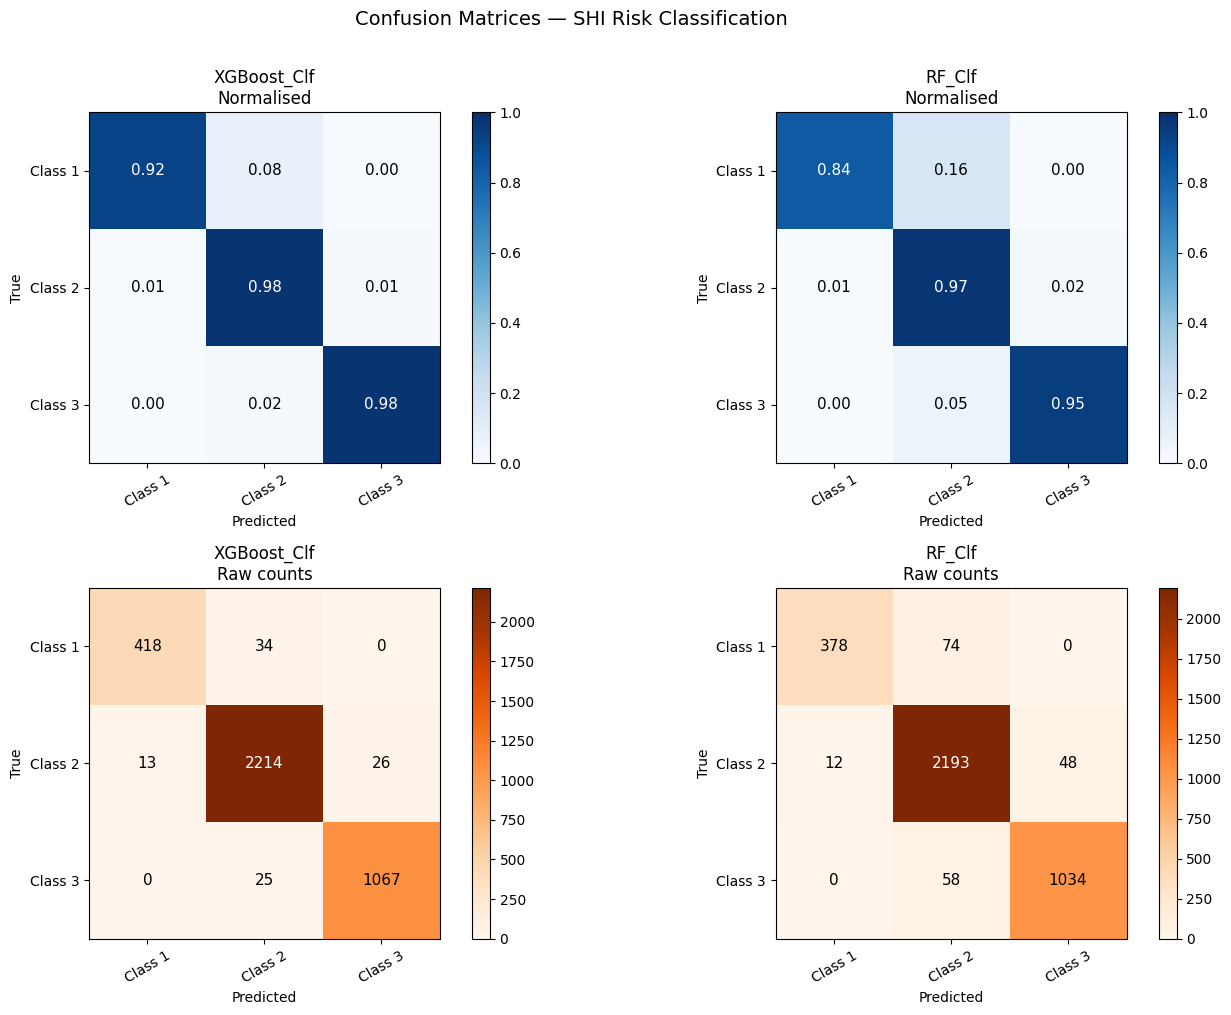

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for j, (name, res) in enumerate(clf_results.items()):
    cm         = res['confusion_matrix']
    cnames     = res['class_names']
    cm_norm    = cm.astype(float) / cm.sum(axis=1, keepdims=True)

    # Row 0 — normalised
    im0 = axes[0, j].imshow(cm_norm, cmap='Blues', vmin=0, vmax=1)
    axes[0, j].set_title(f'{name}\nNormalised', fontsize=12)
    for i in range(len(cnames)):
        for k in range(len(cnames)):
            axes[0, j].text(k, i, f'{cm_norm[i, k]:.2f}',
                            ha='center', va='center',
                            color='white' if cm_norm[i, k] > 0.5 else 'black', fontsize=11)
    axes[0, j].set_xticks(range(len(cnames))); axes[0, j].set_xticklabels(cnames, rotation=30)
    axes[0, j].set_yticks(range(len(cnames))); axes[0, j].set_yticklabels(cnames)
    axes[0, j].set_xlabel('Predicted'); axes[0, j].set_ylabel('True')
    plt.colorbar(im0, ax=axes[0, j])

    # Row 1 — raw counts
    im1 = axes[1, j].imshow(cm, cmap='Oranges')
    axes[1, j].set_title(f'{name}\nRaw counts', fontsize=12)
    for i in range(len(cnames)):
        for k in range(len(cnames)):
            axes[1, j].text(k, i, str(cm[i, k]),
                            ha='center', va='center',
                            color='white' if cm[i, k] > cm.max() * 0.5 else 'black', fontsize=11)
    axes[1, j].set_xticks(range(len(cnames))); axes[1, j].set_xticklabels(cnames, rotation=30)
    axes[1, j].set_yticks(range(len(cnames))); axes[1, j].set_yticklabels(cnames)
    axes[1, j].set_xlabel('Predicted'); axes[1, j].set_ylabel('True')
    plt.colorbar(im1, ax=axes[1, j])

plt.suptitle('Confusion Matrices — SHI Risk Classification', fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()

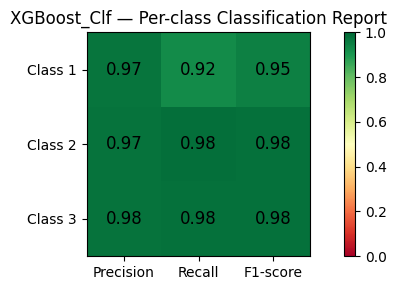


XGBoost_Clf:
               precision    recall  f1-score   support

     Class 1       0.97      0.92      0.95       452
     Class 2       0.97      0.98      0.98      2253
     Class 3       0.98      0.98      0.98      1092

    accuracy                           0.97      3797
   macro avg       0.97      0.96      0.97      3797
weighted avg       0.97      0.97      0.97      3797



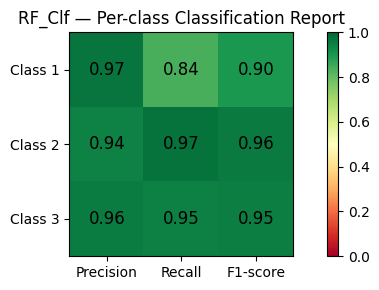


RF_Clf:
               precision    recall  f1-score   support

     Class 1       0.97      0.84      0.90       452
     Class 2       0.94      0.97      0.96      2253
     Class 3       0.96      0.95      0.95      1092

    accuracy                           0.95      3797
   macro avg       0.96      0.92      0.94      3797
weighted avg       0.95      0.95      0.95      3797



precision    recall  f1-score  support
XGBoost_Clf Class 1   0.969838  0.924779  0.946772    452.0
            Class 2   0.974043  0.982690  0.978347   2253.0
            Class 3   0.976212  0.977106  0.976659   1092.0
RF_Clf      Class 1   0.969231  0.836283  0.897862    452.0
            Class 2   0.943226  0.973369  0.958060   2253.0
            Class 3   0.955638  0.946886  0.951242   1092.0

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import classification_report

all_reports = {}

for name, res in clf_results.items():
    report = classification_report(
        res['y_test'], res['y_pred'],
        target_names=res['class_names'],
        output_dict=True
    )
    # Keep only per-class rows (drop accuracy/macro/weighted summary rows)
    per_class = {k: v for k, v in report.items() if k in res['class_names']}
    df = pd.DataFrame(per_class).T[['precision', 'recall', 'f1-score', 'support']]
    all_reports[name] = df

    fig, ax = plt.subplots(figsize=(7, 3))
    im = ax.imshow(df[['precision', 'recall', 'f1-score']].values, cmap='RdYlGn', vmin=0, vmax=1)
    ax.set_xticks([0, 1, 2]); ax.set_xticklabels(['Precision', 'Recall', 'F1-score'])
    ax.set_yticks(range(len(df))); ax.set_yticklabels(df.index)
    for i in range(len(df)):
        for j, col in enumerate(['precision', 'recall', 'f1-score']):
            ax.text(j, i, f'{df[col].iloc[i]:.2f}', ha='center', va='center', fontsize=12)
    plt.colorbar(im, ax=ax)
    ax.set_title(f'{name} — Per-class Classification Report', fontsize=12)
    plt.tight_layout()
    plt.savefig(f'{OUTPUT_DIR}/clf_report_{name}.png', dpi=150, bbox_inches='tight')
    plt.show()
    print(f'\n{name}:\n', classification_report(res['y_test'], res['y_pred'], target_names=res['class_names']))

clf_report_df = pd.concat(all_reports, axis=0)
display(clf_report_df)

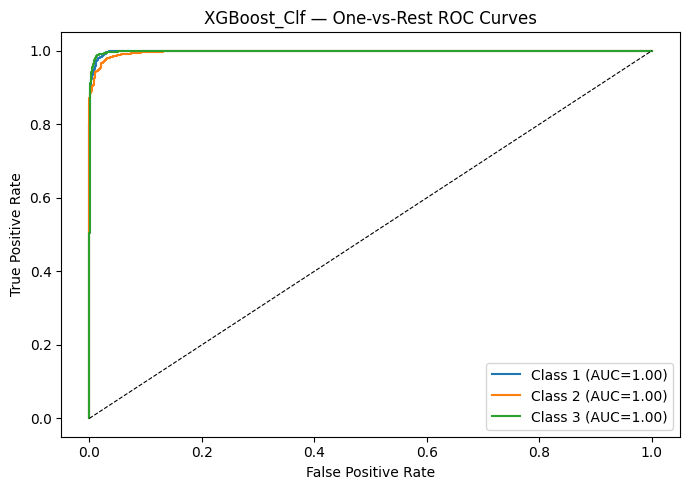

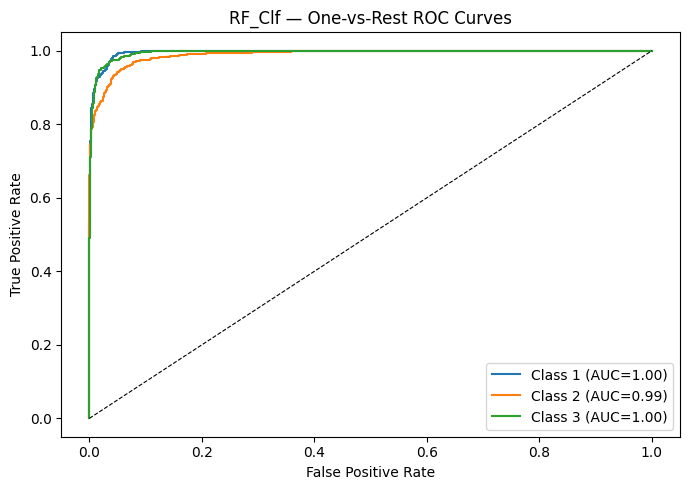

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
import numpy as np

for name, res in clf_results.items():
    y_te    = res['y_test']
    y_proba = res['y_proba']
    cnames  = res['class_names']
    n_cls   = len(cnames)

    fig, ax = plt.subplots(figsize=(7, 5))
    for i in range(n_cls):
        fpr, tpr, _ = roc_curve((y_te == i).astype(int), y_proba[:, i])
        roc_auc = auc(fpr, tpr)
        ax.plot(fpr, tpr, label=f'{cnames[i]} (AUC={roc_auc:.2f})')

    ax.plot([0,1],[0,1],'k--', linewidth=0.8)
    ax.set_xlabel('False Positive Rate'); ax.set_ylabel('True Positive Rate')
    ax.set_title(f'{name} — One-vs-Rest ROC Curves')
    ax.legend(loc='lower right')
    plt.tight_layout()
    plt.savefig(f'{OUTPUT_DIR}/roc_{name}.png', dpi=150, bbox_inches='tight')
    plt.show()

In [ ]:
import pandas as pd

reg_rows = {}
for name, res in model_results.items():
    m = res['metrics']
    reg_rows[name] = {
        'Task':        'Regression',
        'R2':          m.get('R2_test'),
        'RMSE':        m.get('RMSE_test'),
        'MAE':         m.get('MAE_test'),
        'CV_mean':     m.get('R2_cv_mean'),
        'CV_std':      m.get('R2_cv_std'),
        'Accuracy':    None,
        'F1_macro':    None,
        'AUC_OvR':     None,
    }

clf_rows = {}
for name, res in clf_results.items():
    m = res['metrics']
    clf_rows[name] = {
        'Task':        'Classification',
        'R2':          None,
        'RMSE':        None,
        'MAE':         None,
        'CV_mean':     m.get('CV_F1_mean'),
        'CV_std':      m.get('CV_F1_std'),
        'Accuracy':    m.get('Accuracy'),
        'F1_macro':    m.get('F1_macro'),
        'AUC_OvR':     m.get('AUC_OvR'),
    }

full_summary = pd.DataFrame({**reg_rows, **clf_rows}).T
display(full_summary)

,Task,R2,RMSE,MAE,CV_mean,CV_std,Accuracy,F1_macro,AUC_OvR
XGBoost,Regression,0.997215,0.007332,0.004742,0.99727,0.000291,None,None,None
RandomForest,Regression,0.98831,0.015022,0.010186,0.988718,0.000789,None,None,None
XGBoost_Clf,Classification,None,None,None,0.9623,0.0036,0.9742,0.9673,0.9982
RF_Clf,Classification,None,None,None,0.9251,0.0032,0.9494,0.9357,0.9936


---
## Stage 7 — SHAP Explainability

Computing SHAP for XGBoost...


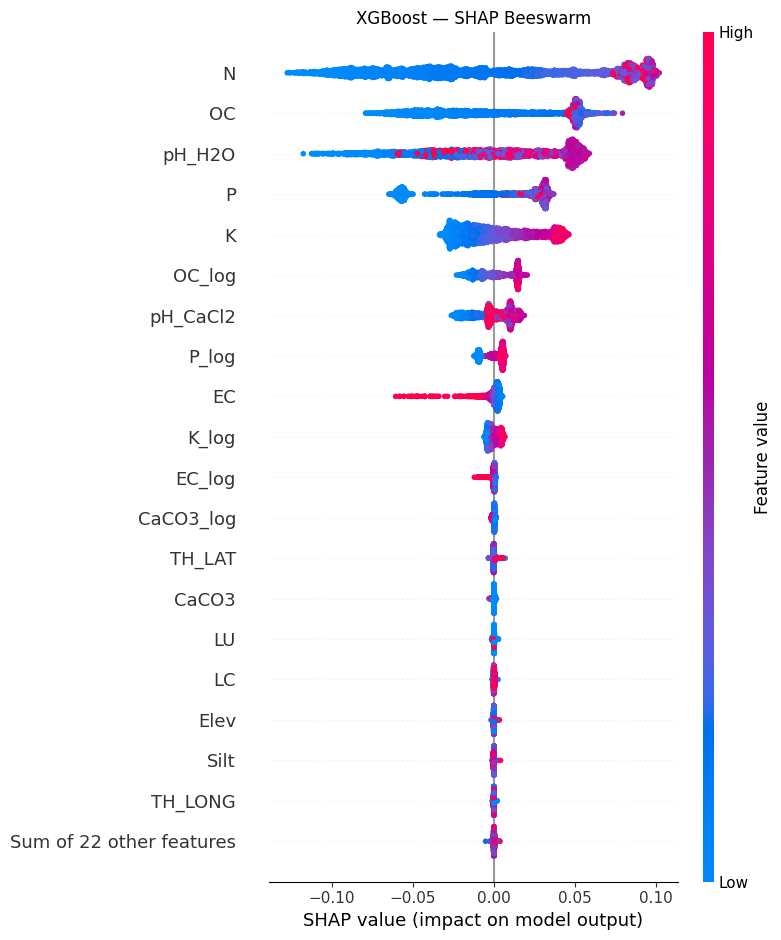

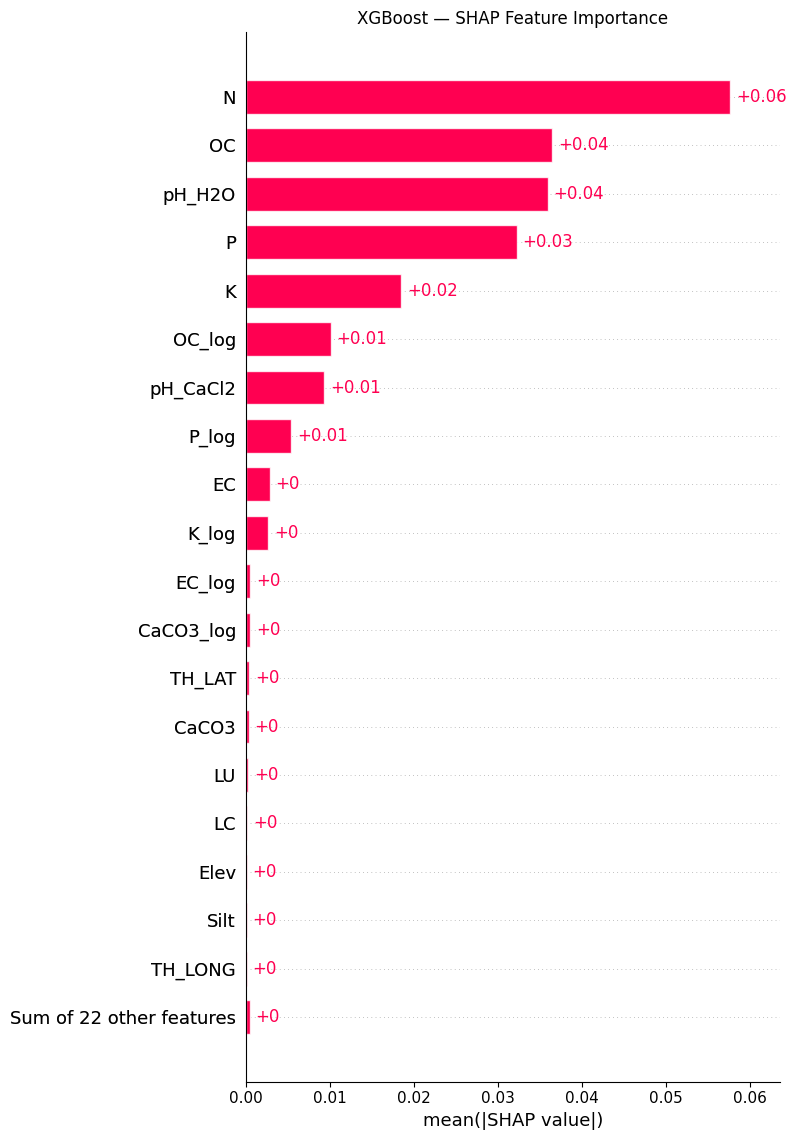

Computing SHAP for RandomForest...


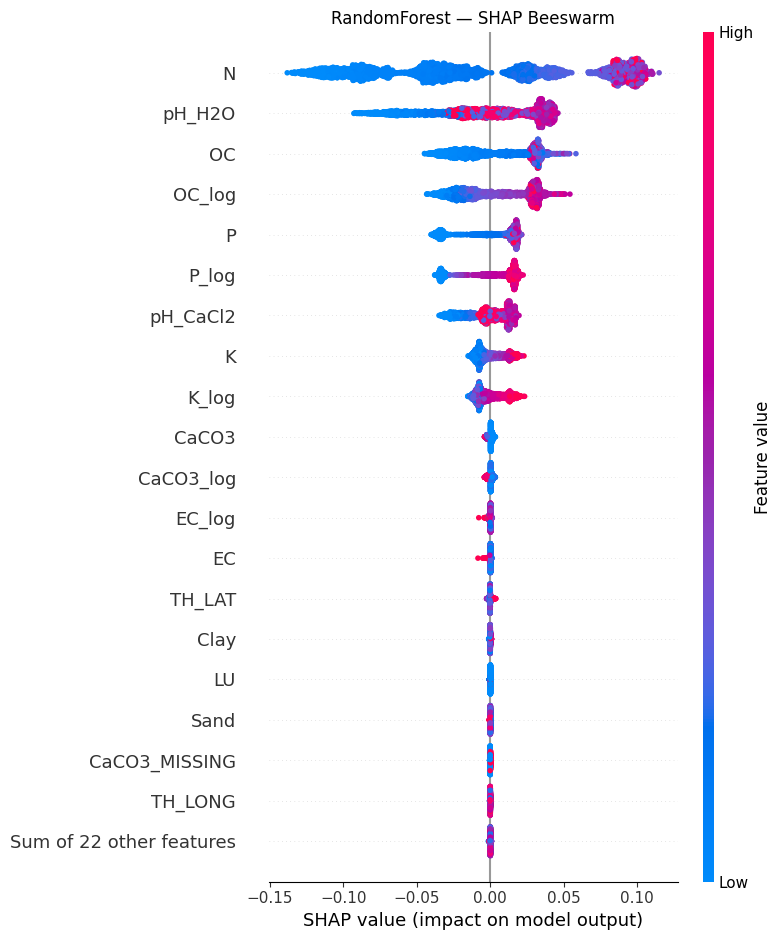

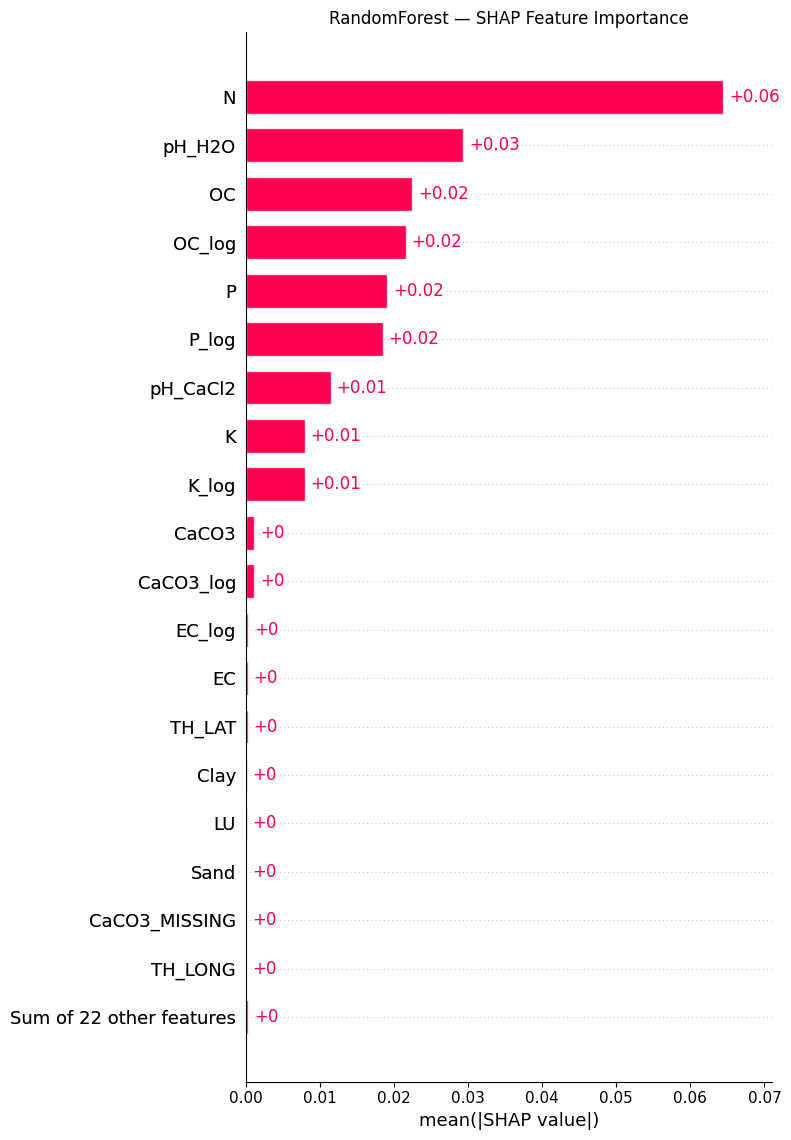

In [ ]:
import shap
import matplotlib.pyplot as plt

shap_results = {}
for name, res in model_results.items():
    model  = res['model']
    X_test = res['X_test']
    print(f'Computing SHAP for {name}...')
    explainer = shap.TreeExplainer(model, feature_perturbation="tree_path_dependent")
    shap_vals = explainer(X_test)
    shap_results[name] = shap_vals

    plt.figure(figsize=(10, 7))
    shap.plots.beeswarm(shap_vals, max_display=20, show=False)
    plt.title(f'{name} — SHAP Beeswarm')
    plt.tight_layout()
    plt.savefig(f'{OUTPUT_DIR}/shap_{name}_beeswarm.png', dpi=150, bbox_inches='tight')
    plt.show()

    plt.figure(figsize=(9, 6))
    shap.plots.bar(shap_vals, max_display=20, show=False)
    plt.title(f'{name} — SHAP Feature Importance')
    plt.tight_layout()
    plt.savefig(f'{OUTPUT_DIR}/shap_{name}_bar.png', dpi=150, bbox_inches='tight')
    plt.show()

DIAGNOSTIC — Most Degraded Point


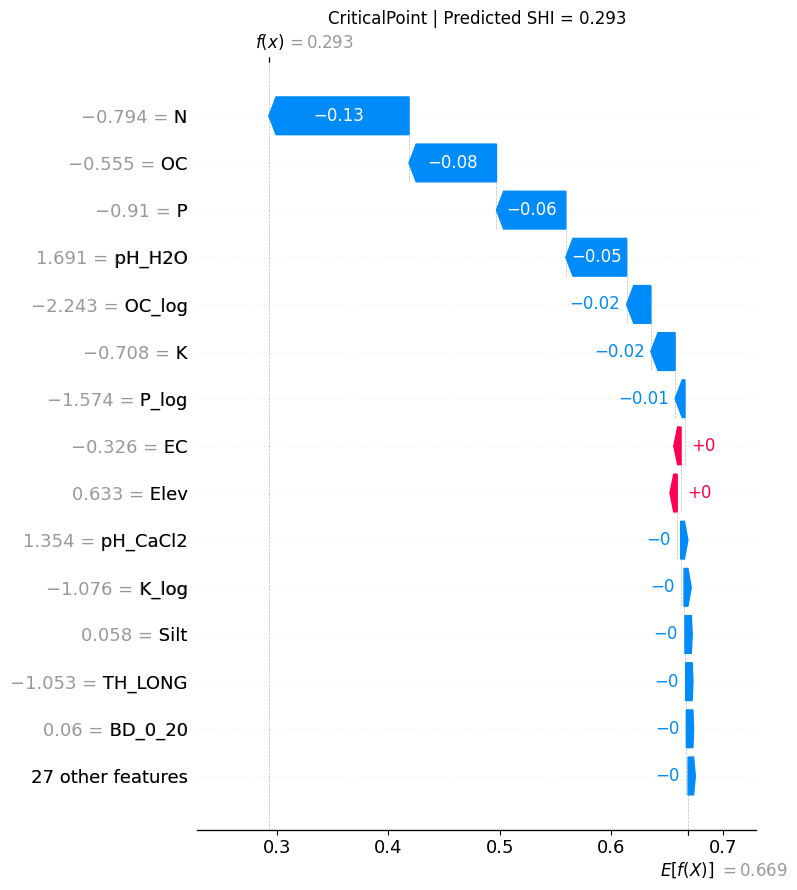

CriticalPoint: SHI = 0.293


In [ ]:
import shap
import pandas as pd
import matplotlib.pyplot as plt

X_test  = model_results[best_name]['X_test']
X_train = model_results[best_name]['X_train']
y_pred  = model_results[best_name]['y_pred']
pred_s  = pd.Series(y_pred, index=X_test.index)

def diagnostic_report(model, point, X_bg, feature_names, point_id, save_dir):
    X_point = point[feature_names].values.reshape(1, -1)
    explainer = shap.TreeExplainer(model, feature_perturbation="tree_path_dependent")
    shap_exp  = explainer(pd.DataFrame(X_point, columns=feature_names))
    shi_pred  = float(model.predict(X_point)[0])
    shap_vals = shap_exp.values[0]

    plt.figure(figsize=(10, 6))
    shap.plots.waterfall(shap_exp[0], max_display=15, show=False)
    plt.title(f'{point_id} | Predicted SHI = {shi_pred:.3f}')
    plt.tight_layout()
    plt.savefig(f'{save_dir}/diagnostic_{point_id}_waterfall.png', dpi=150, bbox_inches='tight')
    plt.show()
    print(f'{point_id}: SHI = {shi_pred:.3f}')

print('DIAGNOSTIC — Most Degraded Point')
diagnostic_report(best_model, X_scaled.loc[pred_s.idxmin()],
                  X_train, feature_names, 'CriticalPoint', OUTPUT_DIR)

DIAGNOSTIC — Healthiest Point


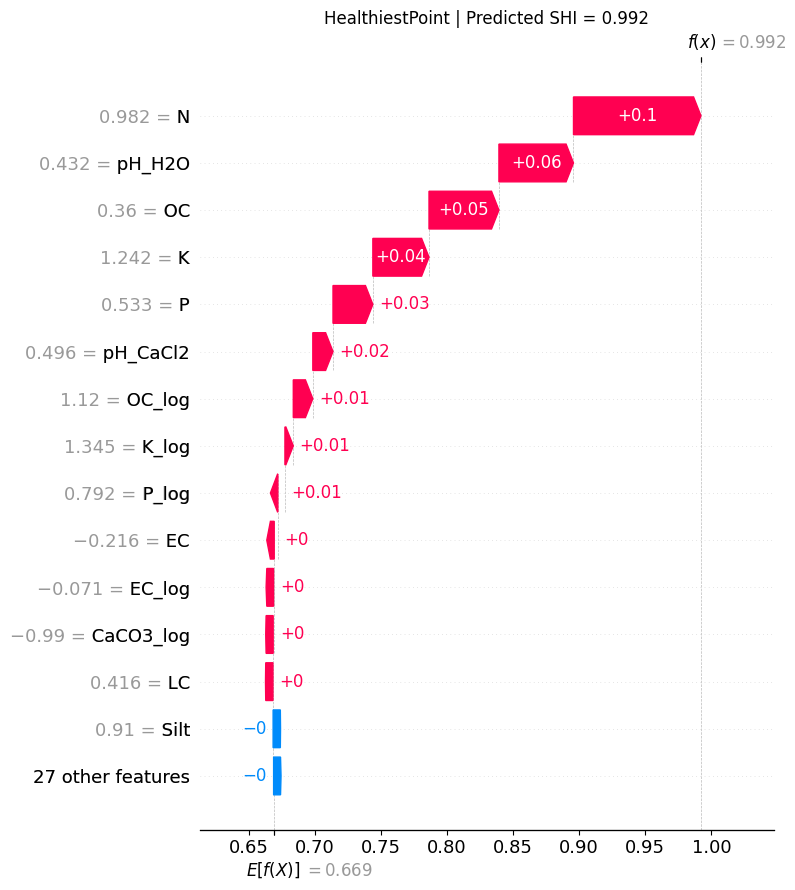

HealthiestPoint: SHI = 0.992


In [ ]:
print('DIAGNOSTIC — Healthiest Point')
diagnostic_report(best_model, X_scaled.loc[pred_s.idxmax()],
                  X_train, feature_names, 'HealthiestPoint', OUTPUT_DIR)

---
## Stage 8 — What-If Scenario Analysis

| Scenario | Intervention |
|----------|--------------|
| Liming | pH +1.5, CaCO₃ +50 g/kg |
| Compost | OC +15 g/kg, N +0.8, P +10 |
| NPK fertiliser | N +1.5, P +30, K +80 |
| Combined | All of the above |

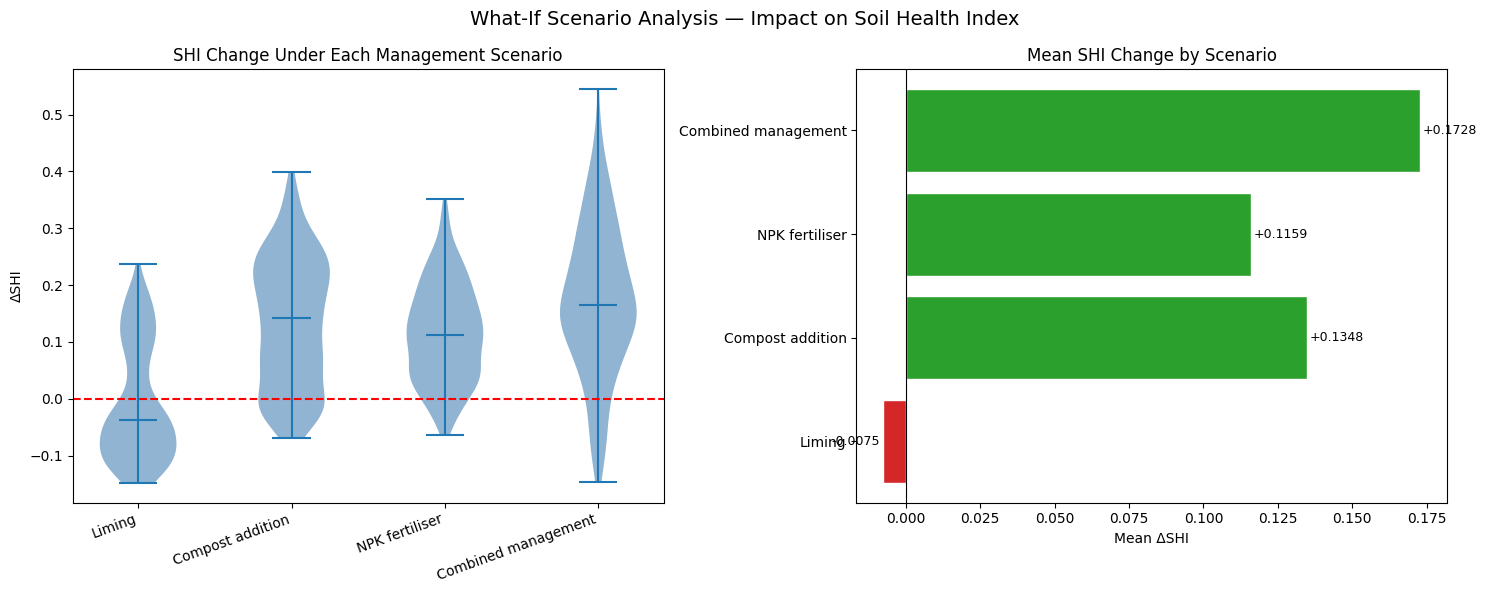

Mean SHI change per scenario:
  Liming                          mean ΔSHI=-0.0075  improved=36.0% of points
  Compost addition                mean ΔSHI=+0.1348  improved=83.0% of points
  NPK fertiliser                  mean ΔSHI=+0.1159  improved=91.0% of points
  Combined management             mean ΔSHI=+0.1728  improved=90.0% of points


In [ ]:
from soil_health_pipeline import run_all_scenarios

scenario_df = run_all_scenarios(
    best_model, X_scaled, feature_names,
    n_sample=500, save_dir=OUTPUT_DIR
)

print('Mean SHI change per scenario:')
delta_cols = [c for c in scenario_df.columns if c.startswith('delta_')]
for col in delta_cols:
    name = col.replace('delta_', '').replace('_', ' ')
    pct_improved = (scenario_df[col] > 0).mean() * 100
    print(f'  {name:30s}  mean ΔSHI={scenario_df[col].mean():+.4f}  improved={pct_improved:.1f}% of points')

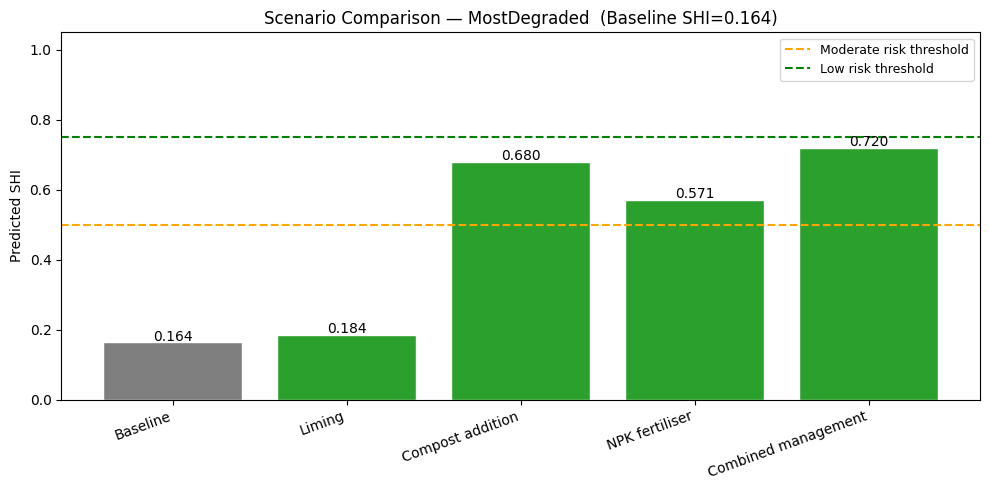

In [ ]:
from soil_health_pipeline import plot_single_scenario
import numpy as np

worst_idx = X_scaled.index[y.loc[X_scaled.index].argmin()]
plot_single_scenario(
    best_model, X_scaled.loc[worst_idx], feature_names,
    save_dir=OUTPUT_DIR, point_id='MostDegraded'
)

In [ ]:
from soil_health_pipeline import simulate_scenario

# Custom intervention — edit values as needed
my_intervention = {
    'pH_H2O': +2.0,
    'OC':     +20.0,
    'N':      +1.0,
    'P':      +20.0,
    'K':      +50.0,
}

shi_before, shi_after = simulate_scenario(
    best_model, X_scaled.loc[worst_idx], my_intervention, feature_names
)
print(f'Custom intervention on most degraded point:')
print(f'  SHI before : {shi_before:.4f}')
print(f'  SHI after  : {shi_after:.4f}')
print(f'  Delta SHI  : {shi_after - shi_before:+.4f}')

Custom intervention on most degraded point:
  SHI before : 0.1636
  SHI after  : 0.7095
  Delta SHI  : +0.5458


---
## Stage 9 — Save All Outputs

In [ ]:
import os, pickle, pandas as pd

df.to_csv(f'{OUTPUT_DIR}/LUCAS_master_with_SHI.csv', index=False)
df.to_parquet(f'{OUTPUT_DIR}/LUCAS_master_with_SHI.parquet', index=False)
print('Saved: LUCAS_master_with_SHI (.csv + .parquet)')

scenario_df.to_csv(f'{OUTPUT_DIR}/scenario_results.csv')
print('Saved: scenario_results.csv')

with open(f'{OUTPUT_DIR}/best_model_{best_name}.pkl', 'wb') as f:
    pickle.dump(best_model, f)
print(f'Saved: best_model_{best_name}.pkl')

with open(f'{OUTPUT_DIR}/scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)
print('Saved: scaler.pkl')

pd.Series(feature_names).to_csv(f'{OUTPUT_DIR}/feature_names.csv', index=False)
print('Saved: feature_names.csv')

reg_metrics  = pd.DataFrame({n: r['metrics'] for n, r in model_results.items()}).T
clf_metrics  = pd.DataFrame({n: r['metrics'] for n, r in clf_results.items()}).T
reg_metrics.to_csv(f'{OUTPUT_DIR}/regression_metrics.csv')
clf_metrics.to_csv(f'{OUTPUT_DIR}/classification_metrics.csv')
print('Saved: regression_metrics.csv + classification_metrics.csv')

print(f'\nAll files in {OUTPUT_DIR}/')
for fname in sorted(os.listdir(OUTPUT_DIR)):
    size = os.path.getsize(f'{OUTPUT_DIR}/{fname}') / 1024
    print(f'  {fname:55s}  {size:8.1f} KB')

Saved: LUCAS_master_with_SHI (.csv + .parquet)
Saved: scenario_results.csv
Saved: best_model_XGBoost.pkl
Saved: scaler.pkl
Saved: feature_names.csv
Saved: regression_metrics.csv + classification_metrics.csv

All files in lucas_output/
  LUCAS_master_with_SHI.csv                                     0.2 KB
  LUCAS_master_with_SHI.parquet                                 2.8 KB
  best_model_XGBoost.pkl                                     1724.1 KB
  classification_metrics.csv                                    0.2 KB
  clf_report_RF_Clf.png                                        36.6 KB
  clf_report_XGBoost_Clf.png                                   36.4 KB
  confusion_matrices.png                                      132.2 KB
  diagnostic_CriticalPoint_waterfall.png                      114.1 KB
  diagnostic_HealthiestPoint_waterfall.png                    115.8 KB
  eda_chemistry_distributions.png                             299.5 KB
  eda_correlation_heatmap.png                          

In [ ]:
from google.colab import files
files.download(f'{OUTPUT_DIR}/LUCAS_master_with_SHI.csv')
files.download(f'{OUTPUT_DIR}/regression_metrics.csv')
files.download(f'{OUTPUT_DIR}/classification_metrics.csv')
files.download(f'{OUTPUT_DIR}/scenario_results.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>